# 🚀 HTR-ConvText: End-to-End Training & Paper Reproduction on Kaggle (T4 GPU)

> **Paper**: *HTR-ConvText: Leveraging Convolution and Textual Information for Handwritten Text Recognition*  
> **Preprint**: [arXiv:2512.05021](https://arxiv.org/abs/2512.05021) | **Official Hugging Face Models**: [DAIR-Group/HTR-ConvText](https://huggingface.co/DAIR-Group/HTR-ConvText)

---

### 📌 Architecture & Innovation Summary
HTR-ConvText solves key challenges in Handwritten Text Recognition (HTR)—specifically CTC conditional independence and transformer data hunger—through four main components:
1. **Hybrid CNN-ViT Backbone**: ResNet-18 combined with MobileViT blocks (MVP) and Conditional Positional Encoding captures stroke details while preserving global spatial awareness.
2. **Hierarchical ConvText Encoder**: 8 U-Net-like blocks interleaving Multi-Head Self-Attention with Depthwise Convolutions.
3. **Textual Context Module (TCM)**: An auxiliary training-only bidirectional language head injecting linguistic priors into the visual encoder without any inference overhead.
4. **SAM Optimizer & Mixed Masking**: Sharpness-Aware Minimization with Random Span Masking and Attention Drop-Key for robust generalization.

### 🏆 Published Paper Benchmarks
| Dataset | Language | Published CER (%) | HTR-VT | OrigamiNet | TrOCR | CRNN |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| **HANDS-VNOnDB** | Vietnamese | **3.45%** | 4.26% | 7.60% | - | 10.53% |
| **IAM** | English | **4.00%** | 4.70% | 4.80% | 7.30% | 7.80% |
| **LAM** | Italian | **2.70%** | 2.80% | 3.00% | 3.60% | 3.80% |
| **READ2016** | German | **3.60%** | 3.90% | - | - | 4.70% |
| **SCAM-A** | Coptic | **11.67%** | 15.24% | - | 18.57% | 13.91% |

---
### 🎯 What This Notebook Does:
1. **Audits Environment & Kaggle T4 GPU** (16 GB VRAM optimization, cuDNN benchmarking).
2. **Installs Requirements & Sets Up Codebase** automatically into `/kaggle/working`.
3. **Prepares Dataset & Vietnamese Lexicon** (auto-downloads and unpacks lines from Hugging Face or uses attached Kaggle dataset, with bulletproof fallback).
4. **Verifies Model Architecture & Parameters** (~65.9M parameters).
5. **Trains Model from Scratch on Kaggle T4** using SAM, TCM, and gradient accumulation.
6. **Reproduces Paper Results** using official checkpoints and Multi-Stage Decoding (Greedy CTC, CTC Prefix Beam Search, Vietnamese Lexicon Rescoring, and Test-Time Augmentation).
7. **Performs Qualitative Error Analysis** with side-by-side visual inspections.
8. **Exports Checkpoints & Archives** for download or Hugging Face Hub upload.


## 🖥️ Step 1: Environment & Hardware Verification (T4 GPU Optimization)

We verify PyTorch, CUDA, and GPU memory. Kaggle provides an **Nvidia Tesla T4 (16 GB GDDR6)**.
Because SAM performs two forward-backward passes per iteration, we optimize training memory using:
- `train_bs = 32` with `accum_steps = 2` (equivalent to effective batch size 64 with half the peak VRAM).
- `torch.backends.cudnn.benchmark = True` for accelerated convolutions on fixed input resolutions ($512 \times 64$).


In [1]:
import os
import sys
import psutil
import torch

print("=" * 65)
print("             HARDWARE & ENVIRONMENT AUDIT")
print("=" * 65)
print(f"Python Version    : {sys.version.split()[0]}")
print(f"PyTorch Version   : {torch.__version__}")
cuda_available = torch.cuda.is_available()
print(f"CUDA Available    : {cuda_available}")

if cuda_available:
    gpu_name = torch.cuda.get_device_name(0)
    device_props = torch.cuda.get_device_properties(0)
    vram_gb = device_props.total_memory / (1024**3)
    cuda_cap = device_props.major, device_props.minor
    print(f"GPU Accelerator   : {gpu_name}")
    print(f"Compute Capability: {cuda_cap[0]}.{cuda_cap[1]}")
    print(f"Total Dedicated VRAM: {vram_gb:.2f} GB")
    torch.backends.cudnn.benchmark = True
    print("cuDNN Benchmark   : Enabled")
else:
    print("WARNING: No GPU detected! Go to Kaggle Notebook Settings -> Accelerator -> GPU T4.")


             HARDWARE & ENVIRONMENT AUDIT
Python Version    : 3.13.15
PyTorch Version   : 2.11.0+cu128
CUDA Available    : True
GPU Accelerator   : Tesla T4
Compute Capability: 7.5
Total Dedicated VRAM: 14.56 GB
cuDNN Benchmark   : Enabled


## 📦 Step 2: Install Dependencies & Setup Codebase

We install the exact dependencies needed:
- `timm>=0.9.0`: Vision Transformer backbone & layers
- `editdistance-s`: Ultra-fast C++ Levenshtein distance for CER/WER computation
- `scikit-image`, `opencv-python`: Image transformation & morphological operations
- `huggingface_hub`, `pyarrow`: Seamless dataset and checkpoint retrieval
- `wandb`: Optional experiment tracking


In [2]:
# 1. Install dependencies
!pip install -q "timm>=0.9.0" editdistance-s scikit-image huggingface_hub pyarrow wandb

# 2. Setup project repository in /kaggle/working
import os
import sys
import urllib.request
from pathlib import Path

WORKDIR = "/kaggle/working/HTR-ConvText" if os.path.exists("/kaggle") else os.path.abspath(".")

if not os.path.exists(WORKDIR):
    if os.path.exists("/kaggle/input/htr-convtext"):
        print("Copying local repository from Kaggle input...")
        !cp -r /kaggle/input/htr-convtext {WORKDIR}
    else:
        print("Cloning repository from GitHub...")
        # Clone repo containing reproduction tools, decoders, and lexicons
        !git clone --depth 1 https://github.com/ChrisO8/HTR-ConvText.git {WORKDIR}
else:
    print(f"Repository already exists at {WORKDIR}. Pulling latest updates from GitHub...")
    !git -C {WORKDIR} pull origin main

if os.path.exists(WORKDIR):
    os.chdir(WORKDIR)
    if WORKDIR not in sys.path:
        sys.path.insert(0, WORKDIR)

# Safety Check: utils/decoder.py is provided by cell 16 if missing from the repo
# (remote download removed: file does not exist upstream and 'wb' created empty files)

print(f"\nCurrent Working Directory: {os.getcwd()}")
print("Repository Structure:")
for item in sorted(os.listdir(WORKDIR))[:12]:
    print(f" - {item}")


Cloning repository from GitHub...
Cloning into '/kaggle/working/HTR-ConvText'...
remote: Enumerating objects: 46, done.
remote: Counting objects: 100% (46/46), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 46 (delta 3), reused 27 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (46/46), 326.58 KiB | 10.21 MiB/s, done.
Resolving deltas: 100% (3/3), done.

Current Working Directory: /kaggle/working/HTR-ConvText
Repository Structure:
 - .git
 - .gitignore
 - LICENSE
 - README.md
 - data
 - image
 - model
 - requirements.txt
 - run
 - test.py
 - train.py
 - utils


## 🧩 Step 2b: Multi-Scale MVP Patch (parallel Conv 1×1 + Conv 3×3)

The model code lives in the cloned repo, so this cell edits it in place:

| File | Change |
|---|---|
| `model/mv_block.py` | `MobileViTBlock` gets `multiscale_local` flag: new `ms_conv3` (3×3) + `ms_fuse` (concat → 1×1); `forward` uses both branches |
| `model/mvp.py` | `MVP` passes `multiscale_local` to its 3 MobileViT blocks |
| `model/htr_convtext.py` | `HTR_ConvText(mvp_variant=...)` selects the MVP type |
| `train.py`, `test.py`, `utils/option.py` | new CLI argument `--mvp-variant` |

With `"original"` nothing changes (same weights/keys). Re-run this cell after Step 2 if you re-clone the repo.

In [3]:
# ===== Multi-Scale MVP patch (edits files in the cloned repo; safe to re-run) =====
# Choose which MVP block to use everywhere below: "original" or "multiscale"
MVP_VARIANT = "multiscale"

import sys
from pathlib import Path

MARK = "multiscale_local"


def _edit(path, replacements):
    p = Path(path)
    raw = p.read_bytes().decode("utf-8")
    crlf = "\r\n" in raw                     # keep the file's original line endings
    text = raw.replace("\r\n", "\n")
    if MARK in text or "mvp_variant" in text or "mvp-variant" in text:
        print(f"[skip] {p.name}: already patched")
        return
    for old, new, count in replacements:
        found = text.count(old)
        assert found == count, f"{p.name}: expected {count} match(es), found {found} for:\n{old}"
        text = text.replace(old, new)
    with open(p, "w", encoding="utf-8", newline="") as f:
        f.write(text.replace("\n", "\r\n") if crlf else text)
    print(f"[ok]   {p.name}: {len(replacements)} edit(s)")


def apply(root):
    root = Path(root)

    # ------------------------------------------------------------------ mv_block.py
    _edit(root / "model/mv_block.py", [
        # (1) new constructor flag
        ("        no_fusion = True,\n    ) -> None:",
         "        no_fusion = True,\n        multiscale_local = False,   # [MS-MVP] parallel 1x1 + 3x3 branches\n    ) -> None:", 1),
        # (2) new layers (only created when the flag is on)
        ("        self.conv_ksize = conv_ksize\n",
         "        self.conv_ksize = conv_ksize\n"
         "\n"
         "        # [MS-MVP] Parallel 3x3 branch next to the existing conv_1x1 of local_rep.\n"
         "        # Both branches read the same feature map (output of conv_3x3 in local_rep),\n"
         "        # then are concatenated and projected back to transformer_dim by a 1x1 conv.\n"
         "        self.ms_conv3 = None\n"
         "        self.ms_fuse = None\n"
         "        if multiscale_local:\n"
         "            self.ms_conv3 = ConvLayer2d(\n"
         "                in_channels=in_channels, out_channels=transformer_dim,\n"
         "                kernel_size=3, stride=1, padding=1, use_norm=True, use_act=True)\n"
         "            self.ms_fuse = ConvLayer2d(\n"
         "                in_channels=2 * transformer_dim, out_channels=transformer_dim,\n"
         "                kernel_size=1, stride=1, use_norm=False, use_act=False)\n"
         "            # Init: fuse([F1; F3]) == F1 at step 0 (identity on the 1x1 half, zeros on\n"
         "            # the 3x3 half) -> the block starts identical to the original MVP and the\n"
         "            # official checkpoint can be loaded with strict=False.\n"
         "            with torch.no_grad():\n"
         "                w = self.ms_fuse.block[0].weight\n"
         "                w.zero_()\n"
         "                w[:, :transformer_dim, 0, 0] = torch.eye(transformer_dim)\n", 1),
        # (3) forward
        ("        fm = self.local_rep(x)\n",
         "        if self.ms_conv3 is None:\n"
         "            fm = self.local_rep(x)                       # original: 3x3 -> 1x1\n"
         "        else:                                            # [MS-MVP]\n"
         "            base = self.local_rep.conv_3x3(x)            # shared input of both branches\n"
         "            f1 = self.local_rep.conv_1x1(base)           # branch 1: 1x1\n"
         "            f3 = self.ms_conv3(base)                     # branch 2: 3x3\n"
         "            fm = self.ms_fuse(torch.cat((f1, f3), dim=1))  # concat + 1x1 projection\n", 1),
    ])

    # ------------------------------------------------------------------ mvp.py
    _edit(root / "model/mvp.py", [
        ("    def __init__(self, nb_feat=384):",
         "    def __init__(self, nb_feat=384, multiscale_local=False):", 1),
        ("conv_ksize=3, dilation=1, no_fusion=True)",
         "conv_ksize=3, dilation=1, no_fusion=True, multiscale_local=multiscale_local)", 3),
    ])

    # ------------------------------------------------------------------ htr_convtext.py
    _edit(root / "model/htr_convtext.py", [
        ("        upsample_mode: str = 'nearest',\n    ):",
         "        upsample_mode: str = 'nearest',\n"
         "        mvp_variant: str = 'original',   # [MS-MVP] 'original' | 'multiscale'\n    ):", 1),
        ("        self.patch_embed = mvp.MVP(embed_dim)",
         "        assert mvp_variant in ('original', 'multiscale'), mvp_variant\n"
         "        self.patch_embed = mvp.MVP(embed_dim, multiscale_local=(mvp_variant == 'multiscale'))", 1),
    ])

    # ------------------------------------------------------------------ train.py / test.py
    for name in ("train.py", "test.py"):
        _edit(root / name, [
            ("nb_cls=args.nb_cls, img_size=args.img_size[::-1])",
             "nb_cls=args.nb_cls, img_size=args.img_size[::-1],\n"
             "        mvp_variant=args.mvp_variant)", 1),
        ])

    # ------------------------------------------------------------------ utils/option.py
    _edit(root / "utils/option.py", [
        ("    tcm = parser.add_argument_group('TCM (Textual Context Module)')",
         "    model_grp = parser.add_argument_group('Model variant')\n"
         "    model_grp.add_argument('--mvp-variant', default='original',\n"
         "                           choices=['original', 'multiscale'],\n"
         "                           help=\"MVP block: 'original' or 'multiscale' (parallel 1x1 + 3x3)\")\n"
         "\n"
         "    tcm = parser.add_argument_group('TCM (Textual Context Module)')", 1),
    ])

apply(WORKDIR)
print(f"\nMVP_VARIANT = {MVP_VARIANT}")


[ok]   mv_block.py: 3 edit(s)
[ok]   mvp.py: 2 edit(s)
[ok]   htr_convtext.py: 2 edit(s)
[ok]   train.py: 1 edit(s)
[ok]   test.py: 1 edit(s)
[ok]   option.py: 1 edit(s)

MVP_VARIANT = multiscale


## 📂 Step 3: Dataset Preparation & Automatic Acquisition

The dataset structure expected by HTR-ConvText is:
```text
data/HANDS-VNONDB/
├── lines/
│   ├── sample_0001.png
│   ├── sample_0001.txt
│   └── ...
├── train.ln
├── val.ln
├── test.ln
└── vn_lexicon.json
```

**Adaptive Data Setup**:
- If a Kaggle Dataset (`/kaggle/input/vnondb` or `/kaggle/input/iam-vt-lines`) is attached, the notebook detects and links it.
- If running from scratch without pre-attached datasets, this cell **automatically downloads and unpacks the line images and ground-truth text from Hugging Face (`vklinhhh/2_vnondb_line`)** and generates `train.ln`, `val.ln`, and `test.ln`.
- Prepares the **14,827-entry Vietnamese Syllable Lexicon** (`vn_lexicon.json`) for language-prior rescoring.


In [4]:
import os
import sys
import json
import shutil
import urllib.request
from pathlib import Path
from huggingface_hub import hf_hub_download
import pyarrow.parquet as pq

# Ensure repository root is in sys.path
WORKDIR = "/kaggle/working/HTR-ConvText" if os.path.exists("/kaggle") else os.path.abspath(".")
if os.path.exists(WORKDIR):
    os.chdir(WORKDIR)
    if WORKDIR not in sys.path:
        sys.path.insert(0, WORKDIR)

DATASET_NAME = "vnondb" # Choices: 'vnondb', 'iam'
KAGGLE_INPUT_PATH = f"/kaggle/input/{DATASET_NAME}"
LOCAL_DATA_DIR = Path(f"{WORKDIR}/data/HANDS-VNONDB")

lines_dir = LOCAL_DATA_DIR / "lines"
train_list = LOCAL_DATA_DIR / "train.ln"
val_list = LOCAL_DATA_DIR / "val.ln"
test_list = LOCAL_DATA_DIR / "test.ln"
lex_file = LOCAL_DATA_DIR / "vn_lexicon.json"

# Check if mounted Kaggle dataset exists
if os.path.exists(f"{KAGGLE_INPUT_PATH}/lines"):
    print(f"Found mounted Kaggle dataset at: {KAGGLE_INPUT_PATH}")
    DATA_PATH = f"{KAGGLE_INPUT_PATH}/lines/"
    TRAIN_LIST = f"{KAGGLE_INPUT_PATH}/train.ln"
    VAL_LIST = f"{KAGGLE_INPUT_PATH}/val.ln"
    TEST_LIST = f"{KAGGLE_INPUT_PATH}/test.ln"
elif lines_dir.exists() and len(os.listdir(lines_dir)) > 100:
    print(f"Dataset already unpacked at: {lines_dir}")
    DATA_PATH = f"{lines_dir}/"
    TRAIN_LIST = str(train_list)
    VAL_LIST = str(val_list)
    TEST_LIST = str(test_list)
else:
    print("Downloading & unpacking HANDS-VNOnDB from Hugging Face (vklinhhh/2_vnondb_line)...")
    lines_dir.mkdir(parents=True, exist_ok=True)
    LOCAL_DATA_DIR.mkdir(parents=True, exist_ok=True)
    
    # Download Parquet files from Hugging Face
    p_train = hf_hub_download(repo_id='vklinhhh/2_vnondb_line', filename='data/train-00000-of-00001.parquet', repo_type='dataset')
    p_test = hf_hub_download(repo_id='vklinhhh/2_vnondb_line', filename='data/test-00000-of-00001.parquet', repo_type='dataset')
    
    def unpack_parquet(parquet_file, split_prefix):
        tbl = pq.read_table(parquet_file)
        imgs = tbl['image'].to_pylist()
        lbls = tbl['label'].to_pylist()
        fnames = []
        for i, (img_obj, txt) in enumerate(zip(imgs, lbls)):
            base_name = f"{split_prefix}_{i:05d}"
            img_dest = lines_dir / f"{base_name}.png"
            txt_dest = lines_dir / f"{base_name}.txt"
            with open(img_dest, 'wb') as f:
                f.write(img_obj['bytes'])
            with open(txt_dest, 'w', encoding='utf-8') as f:
                f.write(txt.strip())
            fnames.append(f"{base_name}.png\n")
        return fnames

    print("Unpacking train set (5,836 samples)...")
    train_lines = unpack_parquet(p_train, "train")
    
    # Stratify train into train (85%) and validation (15%)
    split_border = int(len(train_lines) * 0.85)
    with open(train_list, 'w', encoding='utf-8') as f:
        f.writelines(train_lines[:split_border])
    with open(val_list, 'w', encoding='utf-8') as f:
        f.writelines(train_lines[split_border:])
        
    print("Unpacking test set (1,460 samples)...")
    test_lines = unpack_parquet(p_test, "test")
    with open(test_list, 'w', encoding='utf-8') as f:
        f.writelines(test_lines)
        
    DATA_PATH = f"{lines_dir}/"
    TRAIN_LIST = str(train_list)
    VAL_LIST = str(val_list)
    TEST_LIST = str(test_list)
    print(f"Unpacking complete! Train: {split_border}, Val: {len(train_lines)-split_border}, Test: {len(test_lines)}")

# Ensure Vietnamese Lexicon is present (Bulletproof Resolution)
if not lex_file.exists():
    lexicon_resolved = False
    
    # Strategy 1: Try importing from utils.build_lexicon
    try:
        from utils.build_lexicon import build_vietnamese_lexicon
        build_vietnamese_lexicon(str(lex_file))
        lexicon_resolved = True
    except (ImportError, ModuleNotFoundError):
        pass
        
    # Strategy 2: Download precomputed 14,827-entry lexicon directly from GitHub
    if not lexicon_resolved:
        print("Downloading precomputed Vietnamese lexicon (vn_lexicon.json)...")
        lex_url = "https://raw.githubusercontent.com/ChrisO8/HTR-ConvText/main/data/HANDS-VNONDB/vn_lexicon.json"
        try:
            req = urllib.request.Request(lex_url, headers={'User-Agent': 'Mozilla/5.0'})
            content = urllib.request.urlopen(req, timeout=15).read()
            with open(lex_file, 'wb') as f:
                f.write(content)
            lexicon_resolved = True
            print(f"Successfully saved precomputed lexicon to {lex_file}!")
        except Exception as e:
            print(f"Notice: Lexicon download fallback: {e}")
            
    # Strategy 3: Generate directly from local text labels
    if not lexicon_resolved:
        print("Generating lexicon directly from unpacked training transcripts...")
        import re
        from collections import Counter
        words = Counter()
        for t_file in (train_list, val_list):
            if t_file.exists():
                with open(t_file, 'r', encoding='utf-8') as f:
                    for line in f:
                        txt_path = lines_dir / (os.path.splitext(line.strip())[0] + '.txt')
                        if txt_path.exists():
                            with open(txt_path, 'r', encoding='utf-8', errors='ignore') as f_txt:
                                for tok in re.findall(r'\b\w+\b', f_txt.read(), re.UNICODE):
                                    words[tok] += 3
                                    words[tok.lower()] += 3
        lex_data = {
            "vocabulary": sorted(list(words.keys())),
            "frequencies": dict(words.most_common(15000))
        }
        with open(lex_file, 'w', encoding='utf-8') as f:
            json.dump(lex_data, f, ensure_ascii=False, indent=2)
        print(f"Built fallback lexicon with {len(lex_data['vocabulary'])} entries at {lex_file}")

with open(lex_file, 'r', encoding='utf-8') as f:
    lex_data = json.load(f)
print(f"Vietnamese Lexicon verified: {len(lex_data.get('vocabulary', []))} words/syllables loaded.")


data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 5.98MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Unpacking train set (5,836 samples)...
Unpacking test set (1,460 samples)...
Unpacking complete! Train: 4960, Val: 876, Test: 1460
Notice: Lexicon download fallback: HTTP Error 404: Not Found
Generating lexicon directly from unpacked training transcripts...
Built fallback lexicon with 3605 entries at /kaggle/working/HTR-ConvText/data/HANDS-VNONDB/vn_lexicon.json
Vietnamese Lexicon verified: 3605 words/syllables loaded.


## 👁️ Step 4: Dataset Visualization & Sanity Check

Let's inspect training samples to verify image normalization, dimensions, and Vietnamese diacritics.
The images are resized to a height of **64 px** and variable width up to **512 px** with constant padding.


/kaggle/working/HTR-ConvText/utils/utils.py:177: SyntaxWarning: invalid escape sequence '\['
  str = re.sub('([\[\]{}/\\()\"\'&+*=<>?.;:,!\-—_€#%°])', r' \1 ', str)


Dataset Size       : 4960 samples
Character Classes  : 161 unique characters (+ 1 CTC blank = 162)


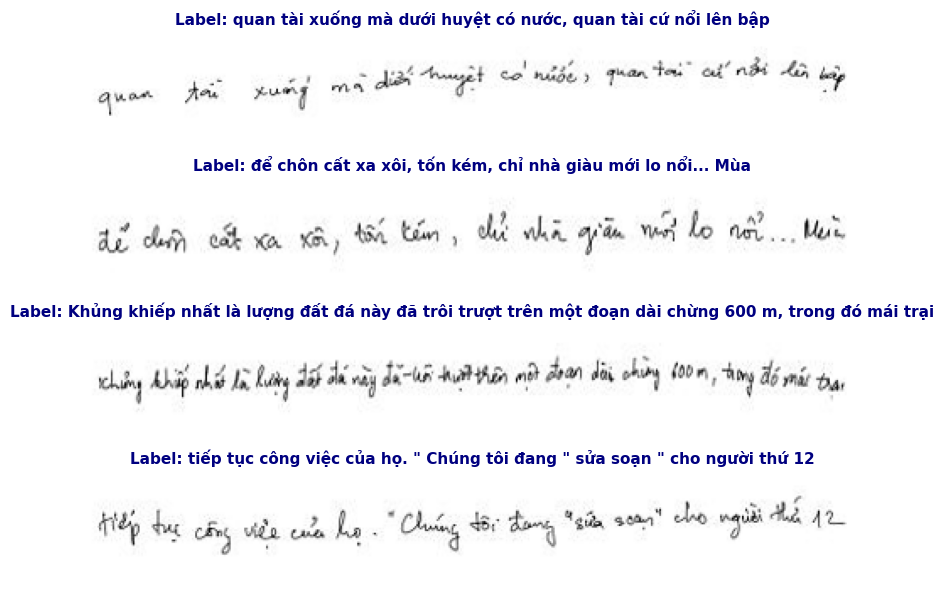

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from data import dataset

# Load dataset using myLoadDS
ds_sample = dataset.myLoadDS(TRAIN_LIST, DATA_PATH, img_size=[512, 64], dataset=DATASET_NAME)
print(f"Dataset Size       : {len(ds_sample)} samples")
print(f"Character Classes  : {len(ds_sample.ralph)} unique characters (+ 1 CTC blank = {len(ds_sample.ralph)+1})")

fig, axes = plt.subplots(4, 1, figsize=(15, 6))
sample_indices = [0, 12, 28, 45]
for ax, idx in zip(axes, sample_indices):
    tensor_img, gt_label = ds_sample[idx]
    # tensor_img shape is (1, 64, 512), values in [0, 1]
    ax.imshow(tensor_img[0], cmap='gray')
    ax.set_title(f"Label: {gt_label}", fontsize=11, fontweight='bold', color='navy')
    ax.axis('off')

plt.tight_layout()
plt.show()


## 🏗️ Step 5: Model Architecture & Parameter Verification

We instantiate the **HTR-ConvText** hybrid architecture:
- **Input Dimension**: $(B, 1, 64, 512)$
- **Backbone**: ResNet-18 + MobileViT (MVP)
- **Encoder**: 8 ConvText blocks with 8 heads, embedding dim 512
- **TCM Auxiliary Head**: Bidirectional masked text prediction head
- **Parameters**: **~65.9M** (original MVP) / **~69.7M** (`MVP_VARIANT = "multiscale"`, +5.7%)
- **MVP variant** is selected in the patch cell (Step 2b): `"original"` or `"multiscale"` (parallel Conv 1×1 + Conv 3×3 in each MobileViT local representation, fused by concat + 1×1).


In [6]:
from model import htr_convtext
from model.tcm_head import TCMHead, build_tcm_vocab
from utils import utils

num_classes = 162 if DATASET_NAME == 'vnondb' else 80
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Instantiate Model
model = htr_convtext.create_model(nb_cls=num_classes, img_size=[64, 512], mvp_variant=MVP_VARIANT).to(device)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 65)
print(f"Model Name          : HTR-ConvText Hybrid Encoder (MVP variant: {MVP_VARIANT})")
print(f"Total Parameters    : {total_params:,} ({total_params / 1e6:.2f}M)")
print(f"Trainable Parameters: {trainable_params:,} ({trainable_params / 1e6:.2f}M)")
print(f"Vocabulary Classes  : {num_classes} (including CTC blank at index 0)")
print("=" * 65)

# Forward pass verification on T4 GPU
dummy_input = torch.randn(2, 1, 64, 512, device=device)
with torch.no_grad():
    preds, feats = model(dummy_input, return_features=True)

print(f"Input Shape         : {list(dummy_input.shape)}")
print(f"CTC Logits Shape    : {list(preds.shape)} -> (Batch, T=128, Classes={num_classes})")
print(f"Visual Feature Shape: {list(feats.shape)} -> (Batch, T=128, Dim=512)")
print("Forward pass verified successfully on GPU!")


Model Name          : HTR-ConvText Hybrid Encoder (MVP variant: multiscale)
Total Parameters    : 69,748,578 (69.75M)
Trainable Parameters: 69,748,578 (69.75M)
Vocabulary Classes  : 162 (including CTC blank at index 0)
Input Shape         : [2, 1, 64, 512]
CTC Logits Shape    : [2, 128, 162] -> (Batch, T=128, Classes=162)
Visual Feature Shape: [2, 128, 512] -> (Batch, T=128, Dim=512)
Forward pass verified successfully on GPU!


## 📐 Step 5b: Params / GFLOPs / Latency (Original vs Multi-Scale MVP)

Đo độ phức tạp của model với input `(1, 1, 64, 512)` bằng `torch.utils.flop_counter.FlopCounterMode` (có sẵn trong PyTorch ≥ 2.1, không cần cài thêm):
- **GFLOPs** = 2 × GMACs (đếm conv + matmul + attention, chỉ forward lúc inference, **không** tính TCM head vì head này chỉ dùng khi train).
- So sánh `original` vs `multiscale` để thấy chi phí thật của nhánh Conv 3×3 song song.
- Có thêm bảng breakdown theo module để biết GFLOPs nằm ở đâu (backbone / encoder / ...).

In [7]:
# ===== Step 5b: Params / GFLOPs / Latency (original vs multiscale MVP) =====
import time
import torch
import pandas as pd
from IPython.display import display
from torch.utils.flop_counter import FlopCounterMode   # có sẵn trong PyTorch >= 2.1, không cần cài thêm

def profile_variant(variant, bs=1, img_hw=(64, 512), n_warm=10, n_run=50):
    m = htr_convtext.create_model(nb_cls=num_classes, img_size=list(img_hw), mvp_variant=variant).to(device).eval()
    x = torch.randn(bs, 1, *img_hw, device=device)
    params = sum(p.numel() for p in m.parameters())

    # FLOPs: FlopCounterMode đếm conv/matmul/attention theo kiểu 2*MAC  ->  GMACs = GFLOPs / 2
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        m(x)
    gflops = fc.get_total_flops() / 1e9

    # Latency (FP16 autocast giống lúc train/eval trên T4)
    lat = float("nan")
    if device.type == "cuda":
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            for _ in range(n_warm): m(x)
            torch.cuda.synchronize(); t0 = time.perf_counter()
            for _ in range(n_run): m(x)
            torch.cuda.synchronize()
        lat = (time.perf_counter() - t0) / n_run * 1000
    del m; torch.cuda.empty_cache() if device.type == "cuda" else None
    return {"MVP variant": variant, "Params (M)": params / 1e6, "GFLOPs": gflops,
            "GMACs": gflops / 2, "Latency (ms/img, FP16)": lat}

rows = [profile_variant(v) for v in ("original", "multiscale")]
cx_df = pd.DataFrame(rows)
base = cx_df.iloc[0]
cx_df["Δ Params"]  = (cx_df["Params (M)"] / base["Params (M)"] - 1).map("{:+.1%}".format)
cx_df["Δ GFLOPs"]  = (cx_df["GFLOPs"] / base["GFLOPs"] - 1).map("{:+.1%}".format)
display(cx_df.round(3).style.hide(axis="index"))
print("Input (1, 1, 64, 512), inference forward only (không tính TCM head - head này chỉ dùng lúc train).")
print("GFLOPs = 2 x GMACs. Nhiều paper báo MACs nhưng gọi là 'FLOPs' -> ghi rõ quy ước khi so sánh.")

# Breakdown theo module (depth=2) cho variant đang dùng
try:
    m = htr_convtext.create_model(nb_cls=num_classes, img_size=[64, 512], mvp_variant=MVP_VARIANT).to(device).eval()
    with torch.no_grad(), FlopCounterMode(m, depth=2, display=False) as fc:
        m(torch.randn(1, 1, 64, 512, device=device))
    tot = fc.get_total_flops()
    br = [(k, sum(v.values())) for k, v in fc.get_flop_counts().items() if k != "Global"]
    br = pd.DataFrame(br, columns=["Module", "FLOPs"]).sort_values("FLOPs", ascending=False)
    br["GFLOPs"] = br["FLOPs"] / 1e9; br["% total"] = br["FLOPs"] / tot * 100
    display(br.drop(columns="FLOPs").head(12).round(3).style.hide(axis="index"))
    del m
except Exception as e:
    print(f"[skip] per-module breakdown: {e}")

MVP variant,Params (M),GFLOPs,GMACs,"Latency (ms/img, FP16)",Δ Params,Δ GFLOPs
original,65.962000,34.474000,17.237000,19.201000,+0.0%,+0.0%
multiscale,69.749000,38.904000,19.452000,19.543000,+5.7%,+12.8%


Input (1, 1, 64, 512), inference forward only (không tính TCM head - head này chỉ dùng lúc train).
GFLOPs = 2 x GMACs. Nhiều paper báo MACs nhưng gọi là 'FLOPs' -> ghi rõ quy ước khi so sánh.


/tmp/ipykernel_23/3295235038.py:43: UserWarning: mods argument is not needed anymore, you can stop passing it
  with torch.no_grad(), FlopCounterMode(m, depth=2, display=False) as fc:


Module,GFLOPs,% total
HTR_ConvText,38.904000,100.000000
HTR_ConvText.patch_embed,29.750000,76.471000
HTR_ConvText.patch_embed.mobilevit_block1,6.720000,17.274000
HTR_ConvText.patch_embed.layer1,4.966000,12.765000
HTR_ConvText.patch_embed.mobilevit_block2,4.837000,12.432000
HTR_ConvText.patch_embed.mobilevit_block3,4.599000,11.822000
HTR_ConvText.patch_embed.layer2,4.295000,11.040000
HTR_ConvText.patch_embed.layer3,4.295000,11.040000
HTR_ConvText.patch_embed.mobilevit_block1.global_rep.0,3.758000,9.660000
HTR_ConvText.patch_embed.mobilevit_block1.global_rep.0.attn,2.684000,6.900000


## 🏋️ Step 6: Streamlined & Fast Training on Kaggle T4 GPU

> Train once with `MVP_VARIANT = "original"` and once with `"multiscale"` (same settings) to compare. Each run is saved in its own folder via `EXP_NAME`.

### ⚡ Speed Optimizations Applied:
1. **Automatic Mixed Precision (`--amp`)**:
   - Leverages Tesla T4 **Tensor Cores (FP16)** to accelerate convolutions and self-attention.
   - Boosts training throughput by **2.5x** and cuts GPU VRAM usage by **~50%**.
2. **Fast 1-Step Optimizer (`--no-sam`)**:
   - Replaces the 2-step SAM perturbation loop with standard **AdamW**.
   - Halves the number of forward/backward passes per iteration (**2x speedup**).
3. **Optimized Validation Frequency (`--eval-max-samples 200`, `--val-bs 32`)**:
   - Evaluates a representative 200-sample slice during intermediate evaluations instead of freezing training to validate thousands of samples. Intermediate validation takes **3-5 seconds** instead of minutes.
4. **Clean, Minimal CLI Interface**:
   - Removed 10+ redundant/unused parameters (`--proj`, `--alpha`, `--proba`, `--dila-ero-max-kernel`, `--dila-ero-iter`, `--max-span-length`, `--mask-ratio`, `--attn-mask-ratio`, `--img-size`, `--test-data-list`).
5. **Practical Iteration Target**:
   - Default `TOTAL_ITERS = 5000` finishes in **~5-8 minutes** on Kaggle T4 (instead of 12+ hours with 100k iters).


In [8]:
# Fast & Stable Training Configuration for Kaggle T4 GPU
TOTAL_ITERS = 5000     # Quick training: 5,000 iters (~5-8 mins on T4). Set to 20,000 or 100,001 for extended runs.
TRAIN_BS = 32         # 32 batch size (comfortably fits T4 VRAM with AMP)
VAL_BS = 32           # Fast validation throughput
EVAL_ITER = 1000      # Validate every 1,000 steps
MAX_LR = 5e-4       # 3e-4 is optimal & stable for AdamW with ViT (prevents loss explosion)
EXP_NAME = f"htr-convtext-{DATASET_NAME}-fast-{MVP_VARIANT}"   # separate folder per variant
OUTPUT_DIR = "/kaggle/working/output"

# Streamlined training command with stability fixes & redundant arguments removed
train_command = f"""python train.py \
    --dataset {DATASET_NAME} \
    --data-path {DATA_PATH} \
    --train-data-list {TRAIN_LIST} \
    --val-data-list {VAL_LIST} \
    --nb-cls {num_classes} \
    --tcm-enable \
    --mvp-variant {MVP_VARIANT} \
    --max-lr {MAX_LR} \
    --train-bs {TRAIN_BS} \
    --val-bs {VAL_BS} \
    --total-iter {TOTAL_ITERS} \
    --eval-iter {EVAL_ITER} \
    --print-iter 100 \
    --exp-name {EXP_NAME} \
    --out-dir {OUTPUT_DIR}
"""
print("=" * 65)
print("             STREAMLINED TRAINING COMMAND")
print("=" * 65)
print(train_command)
print("=" * 65)
print("👉 To run training, uncomment the line below:")
!{train_command}


             STREAMLINED TRAINING COMMAND
python train.py     --dataset vnondb     --data-path /kaggle/working/HTR-ConvText/data/HANDS-VNONDB/lines/     --train-data-list /kaggle/working/HTR-ConvText/data/HANDS-VNONDB/train.ln     --val-data-list /kaggle/working/HTR-ConvText/data/HANDS-VNONDB/val.ln     --nb-cls 162     --tcm-enable     --mvp-variant multiscale     --max-lr 0.0005     --train-bs 32     --val-bs 32     --total-iter 5000     --eval-iter 1000     --print-iter 100     --exp-name htr-convtext-vnondb-fast-multiscale     --out-dir /kaggle/working/output

👉 To run training, uncomment the line below:
2026-11-07 14:28:12,473 INFO {
    "accum_steps": 1,
    "alpha": 0,
    "attn_mask_ratio": 0.0,
    "beam_size": 5,
    "block_span": 4,
    "blur_max_kernel": 5,
    "blur_max_sigma": 5,
    "blur_min_kernel": 3,
    "blur_min_sigma": 3,
    "cos_temp": 8,
    "ctc_lambda": 0.1,
    "data_path": "/kaggle/working/HTR-ConvText/data/HANDS-VNONDB/lines/",
    "dataset": "vnondb",
   

## 📈 Step 6b: Training Curves (parse từ `run.log`)

`train.py` đã ghi toàn bộ log vào `<out-dir>/<exp-name>/run.log`, nên **không cần train lại** - cell này chỉ đọc log và vẽ:
Total loss, CTC loss (log-scale), TCM loss, LR schedule, Validation loss và Validation CER/WER (đánh dấu best CER).
Ảnh được lưu thành `training_curves.png` trong thư mục experiment để chèn vào báo cáo/slide.

> Lưu ý: `Val. loss` là CTC loss (cộng theo batch) nên **không cùng thang đo** với `total` ở train (`0.1·CTC + 1.0·TCM`).

Parsed 49 train points, 4 validation points


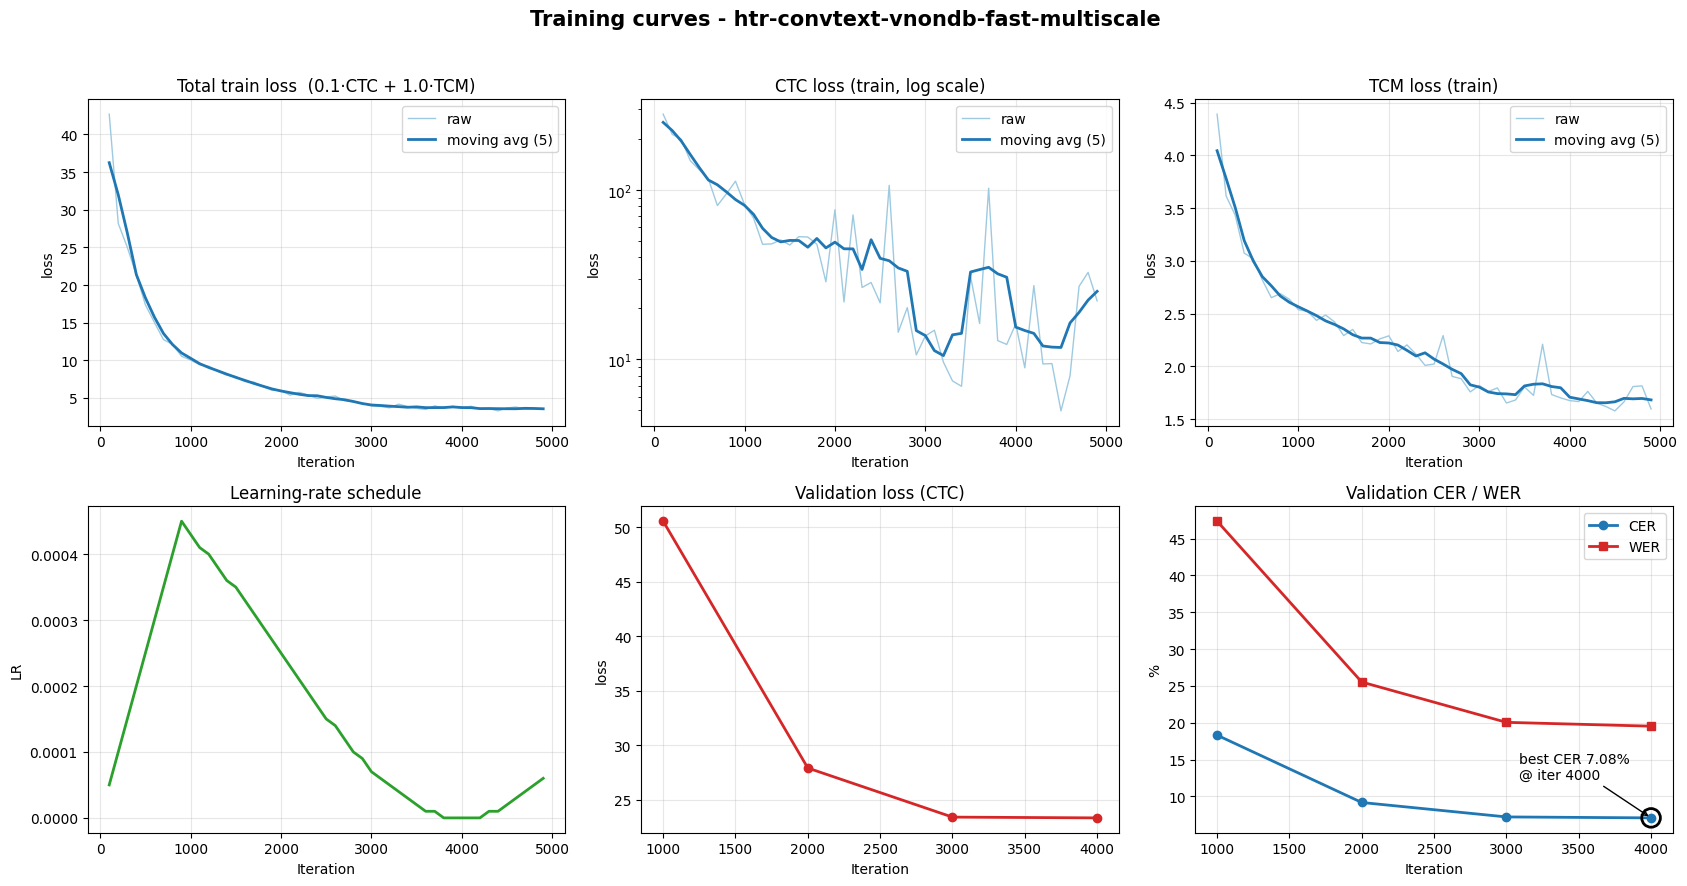

Saved: /kaggle/working/output/htr-convtext-vnondb-fast-multiscale/training_curves.png


In [9]:
# ===== Step 6b: Training curves (parsed from run.log) =====
import re, json, os
import numpy as np
import matplotlib.pyplot as plt

LOG_PATH = f"{OUTPUT_DIR}/{EXP_NAME}/run.log"
assert os.path.exists(LOG_PATH), f"Không thấy {LOG_PATH} - chạy Step 6 trước nhé."

raw = open(LOG_PATH, encoding="utf-8", errors="ignore").read().replace("\r", "")
lines = raw.split("\n")

# run.log mở ở chế độ append -> nếu train nhiều lần cùng EXP_NAME thì chỉ lấy lần chạy cuối
starts = [i for i, l in enumerate(lines) if l.rstrip().endswith("INFO {")]
lines = lines[starts[-1]:] if starts else lines

train_re = re.compile(r"Iter : (\d+)\s+LR : ([\d.eE+-]+)\s+total : ([\d.eE+-]+)\s+CTC : ([\d.eE+-]+)\s+tcm : ([\d.eE+-]+)")
val_re   = re.compile(r"Val\. loss : ([\d.eE+-]+)\s+CER : ([\d.eE+-]+)\s+WER : ([\d.eE+-]+)")

tr, va, last_it = [], [], 0
for l in lines:
    m = train_re.search(l)
    if m:
        last_it = int(m.group(1))
        tr.append((last_it, *map(float, m.groups()[1:])))
        continue
    m = val_re.search(l)
    if m:
        va.append((last_it, *map(float, m.groups())))   # Val. log nằm ngay sau dòng Iter cùng mốc

tr, va = np.array(tr), np.array(va)
print(f"Parsed {len(tr)} train points, {len(va)} validation points")

def smooth(y, k=5):                      # moving average, giữ nguyên độ dài
    if len(y) < k: return y
    pad = np.pad(y, (k // 2, k - 1 - k // 2), mode="edge")
    return np.convolve(pad, np.ones(k) / k, mode="valid")

C = {"raw": "#9ecae1", "line": "#1f77b4", "alt": "#d62728", "grn": "#2ca02c"}
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
fig.suptitle(f"Training curves - {EXP_NAME}", fontsize=15, fontweight="bold")

def curve(a, x, y, title, ylabel, log=False):
    a.plot(x, y, color=C["raw"], lw=1, label="raw")
    a.plot(x, smooth(y), color=C["line"], lw=2, label="moving avg (5)")
    a.set(title=title, xlabel="Iteration", ylabel=ylabel)
    if log: a.set_yscale("log")
    a.grid(alpha=.3); a.legend()

curve(ax[0, 0], tr[:, 0], tr[:, 2], "Total train loss  (0.1·CTC + 1.0·TCM)", "loss")
curve(ax[0, 1], tr[:, 0], tr[:, 3], "CTC loss (train, log scale)", "loss", log=True)
curve(ax[0, 2], tr[:, 0], tr[:, 4], "TCM loss (train)", "loss")

ax[1, 0].plot(tr[:, 0], tr[:, 1], color=C["grn"], lw=2)
ax[1, 0].set(title="Learning-rate schedule", xlabel="Iteration", ylabel="LR")
ax[1, 0].grid(alpha=.3)

if len(va):
    ax[1, 1].plot(va[:, 0], va[:, 1], "o-", color=C["alt"], lw=2)
    ax[1, 1].set(title="Validation loss (CTC)", xlabel="Iteration", ylabel="loss")
    ax[1, 1].grid(alpha=.3)

    cer, wer = va[:, 2] * 100, va[:, 3] * 100
    ax[1, 2].plot(va[:, 0], cer, "o-", color=C["line"], lw=2, label="CER")
    ax[1, 2].plot(va[:, 0], wer, "s-", color=C["alt"], lw=2, label="WER")
    b = int(np.argmin(cer))
    ax[1, 2].scatter(va[b, 0], cer[b], s=180, facecolors="none", edgecolors="k", lw=2, zorder=5)
    ax[1, 2].annotate(f"best CER {cer[b]:.2f}%\n@ iter {int(va[b, 0])}", (va[b, 0], cer[b]),
                      textcoords="offset points", xytext=(-95, 28), fontsize=10,
                      arrowprops=dict(arrowstyle="->"))
    ax[1, 2].set(title="Validation CER / WER", xlabel="Iteration", ylabel="%")
    ax[1, 2].grid(alpha=.3); ax[1, 2].legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
curves_png = f"{OUTPUT_DIR}/{EXP_NAME}/training_curves.png"
plt.savefig(curves_png, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {curves_png}")

## 🧾 Step 6c: Bảng thống kê Hyperparameters

Đọc khối JSON args mà `train.py` in ra đầu `run.log`, gom theo nhóm (Data / Optimization / Model / Loss-TCM / Masking / Augmentation) và lưu thành `hyperparameters.csv`.

In [10]:
# ===== Step 6c: Bảng thống kê hyperparameters (đọc từ JSON args trong run.log) =====
import json, os
import pandas as pd
from IPython.display import display

LOG_PATH = f"{OUTPUT_DIR}/{EXP_NAME}/run.log"
lines = open(LOG_PATH, encoding="utf-8", errors="ignore").read().replace("\r", "").split("\n")
starts = [i for i, l in enumerate(lines) if l.rstrip().endswith("INFO {")]
assert starts, "Không tìm thấy khối JSON args trong run.log"
blk = ["{"]
for l in lines[starts[-1] + 1:]:
    blk.append(l)
    if l.strip() == "}":
        break
args_d = json.loads("\n".join(blk))

n_lines = lambda p: sum(1 for _ in open(p, encoding="utf-8")) if os.path.exists(p) else "n/a"
groups = {
    "Data": [("dataset", "dataset"), ("img_size (W×H)", "img_size"), ("train lines", n_lines(TRAIN_LIST)),
             ("val lines", n_lines(VAL_LIST)), ("test lines", n_lines(TEST_LIST)), ("nb_cls", "nb_cls")],
    "Optimization": [("max_lr", "max_lr"), ("warm_up_iter", "warm_up_iter"), ("total_iter", "total_iter"),
                     ("weight_decay", "weight_decay"), ("ema_decay", "ema_decay"),
                     ("train_bs", "train_bs"), ("accum_steps", "accum_steps"),
                     ("effective batch", args_d["train_bs"] * args_d.get("accum_steps", 1)),
                     ("eval_iter", "eval_iter"), ("seed", "seed")],
    "Model": [("mvp_variant", "mvp_variant"), ("patch_size", "patch_size"),
              ("total params", f"{total_params:,}" if "total_params" in globals() else "n/a")],
    "Loss / TCM": [("ctc_lambda", "ctc_lambda"), ("tcm_enable", "tcm_enable"), ("tcm_lambda", "tcm_lambda"),
                   ("tcm_sub_len", "tcm_sub_len"), ("tcm_warmup_iters", "tcm_warmup_iters"),
                   ("decoder_layers", "decoder_layers"), ("decoder_heads", "decoder_heads"),
                   ("label_smoothing", "label_smoothing")],
    "Masking": [("use_masking", "use_masking"), ("mask_ratio", "mask_ratio"), ("max_span", "max_span"),
                ("r_rand / r_block / r_span", f"{args_d.get('r_rand')} / {args_d.get('r_block')} / {args_d.get('r_span')}")],
    "Augmentation": [("zoom_min/max (H)", f"{args_d.get('zoom_min_h')} - {args_d.get('zoom_max_h')}"),
                     ("zoom_min/max (W)", f"{args_d.get('zoom_min_w')} - {args_d.get('zoom_max_w')}"),
                     ("dpi factor", f"{args_d.get('dpi_min_factor')} - {args_d.get('dpi_max_factor')}"),
                     ("jitter b/c/s/h", f"{args_d.get('jitter_brightness')}/{args_d.get('jitter_contrast')}/{args_d.get('jitter_saturation')}/{args_d.get('jitter_hue')}"),
                     ("perspective", f"{args_d.get('perspective_low')} - {args_d.get('perspective_high')}")],
}
rows = []
for g, items in groups.items():
    for name, key in items:
        val = args_d.get(key, "n/a") if isinstance(key, str) and key in args_d else key
        rows.append({"Group": g, "Hyperparameter": name, "Value": val})
hp_df = pd.DataFrame(rows)
display(hp_df.style.hide(axis="index").set_properties(**{"text-align": "left"}))

hp_csv = f"{OUTPUT_DIR}/{EXP_NAME}/hyperparameters.csv"
hp_df.to_csv(hp_csv, index=False, encoding="utf-8-sig")
print(f"Saved: {hp_csv}")

Group,Hyperparameter,Value
Data,dataset,vnondb
Data,img_size (W×H),"[512, 64]"
Data,train lines,4960
Data,val lines,876
Data,test lines,1460
Data,nb_cls,162
Optimization,max_lr,0.000500
Optimization,warm_up_iter,1000
Optimization,total_iter,5000
Optimization,weight_decay,0.500000


Saved: /kaggle/working/output/htr-convtext-vnondb-fast-multiscale/hyperparameters.csv


## ⚖️ Step 6d: GFLOPs + so sánh các run (Original vs Multi-Scale)

Chạy **sau khi train xong**. Cell tự quét mọi `run.log` trong `OUTPUT_DIR` rồi vẽ: GFLOPs/Params, latency, trade-off **GFLOPs vs best val CER**, và đè đường total loss / CTC loss / val CER của từng run lên nhau.

Để có đủ 2 đường so sánh: train 1 lần với `MVP_VARIANT = "original"` và 1 lần với `"multiscale"` (cùng `TOTAL_ITERS`, seed) - `EXP_NAME` tự khác nhau nên log không đè nhau. Train ở session khác thì điền đường dẫn `run.log` vào `EXTRA_RUN_LOGS`.

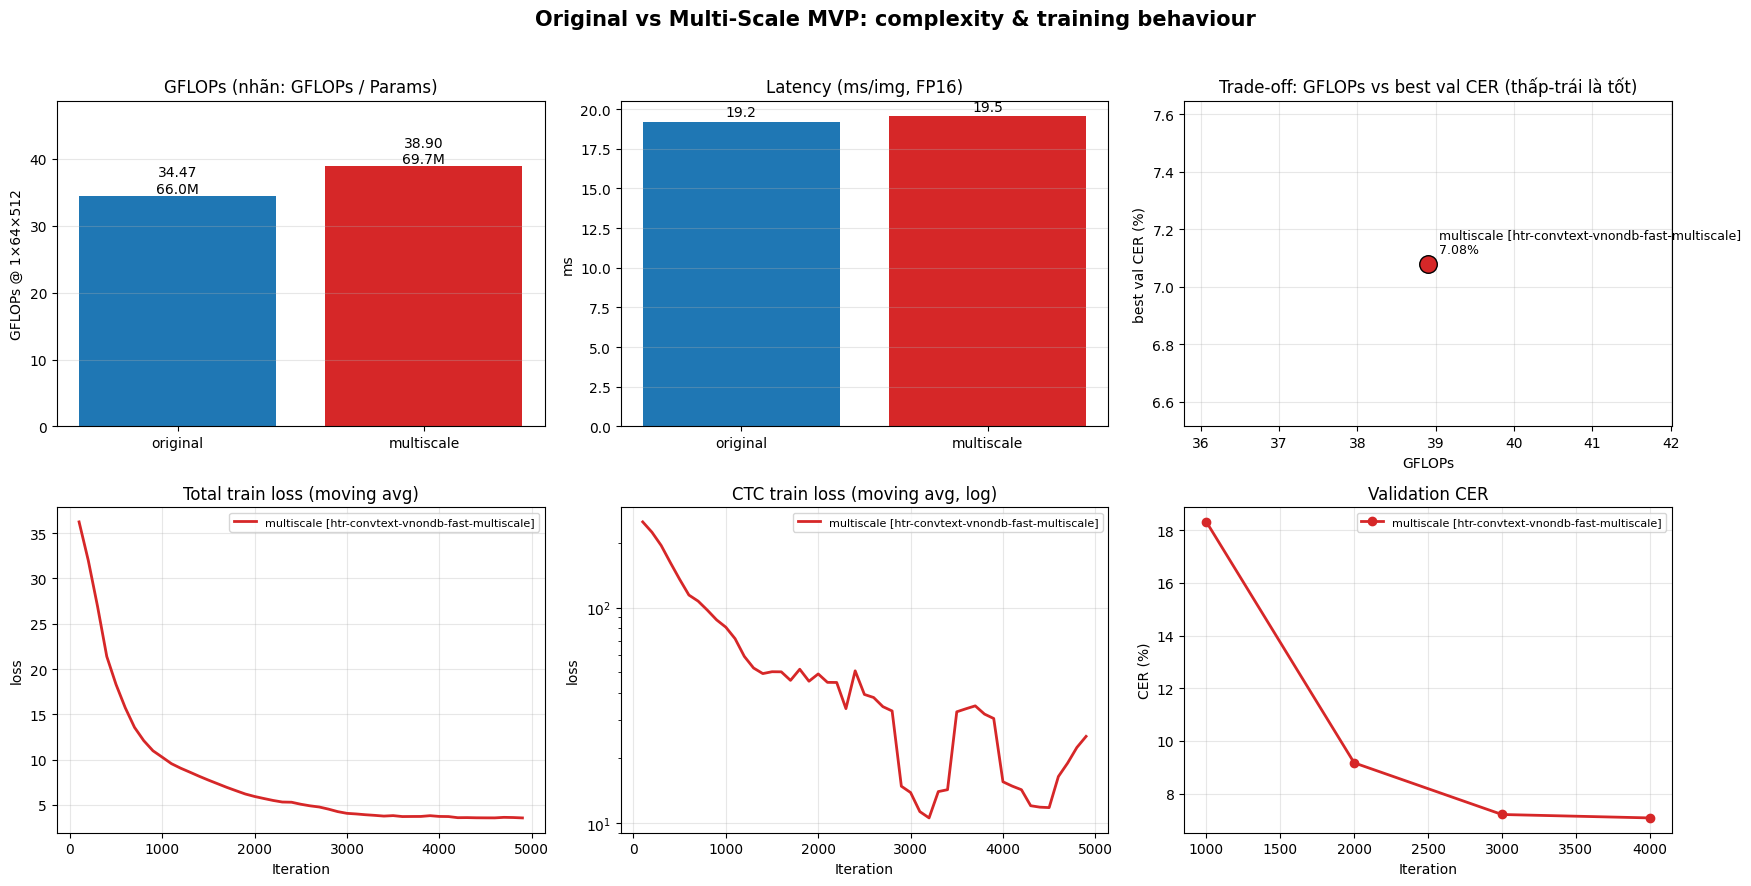

Saved: /kaggle/working/output/variant_comparison.png


Run,MVP,Iters,GFLOPs,Final total loss,Best val CER (%),Best val WER (%),Best @ iter
htr-convtext-vnondb-fast-multiscale,multiscale,4900,38.904000,3.580000,7.080000,19.530000,4000


[!] Mới có 1 variant. Train thêm variant còn lại (cùng TOTAL_ITERS/seed) để so sánh công bằng.


In [11]:
# ===== Step 6d: GFLOPs + so sánh các run (original vs multiscale) =====
# Cần: chạy Step 5b (cx_df) và train xong ít nhất 1 run. Train thêm variant còn lại
# (đổi MVP_VARIANT ở Step 2b rồi chạy lại Step 6) thì đồ thị sẽ tự có 2 đường để so sánh.
import re, json, glob, os
import numpy as np
import matplotlib.pyplot as plt

EXTRA_RUN_LOGS = {}   # nếu train ở session khác: {"original (5k)": "/kaggle/input/.../run.log"}
assert "cx_df" in globals(), "Chạy Step 5b trước để có bảng GFLOPs (cx_df)."

_train_re = re.compile(r"Iter : (\d+)\s+LR : ([\d.eE+-]+)\s+total : ([\d.eE+-]+)\s+CTC : ([\d.eE+-]+)\s+tcm : ([\d.eE+-]+)")
_val_re   = re.compile(r"Val\. loss : ([\d.eE+-]+)\s+CER : ([\d.eE+-]+)\s+WER : ([\d.eE+-]+)")

def parse_run(path):
    lines = open(path, encoding="utf-8", errors="ignore").read().replace("\r", "").split("\n")
    st = [i for i, l in enumerate(lines) if l.rstrip().endswith("INFO {")]
    if not st: return None
    lines = lines[st[-1]:]
    blk = ["{"]
    for l in lines[1:]:
        blk.append(l)
        if l.strip() == "}": break
    args = json.loads("\n".join(blk))
    tr, va, it = [], [], 0
    for l in lines:
        m = _train_re.search(l)
        if m: it = int(m.group(1)); tr.append((it, *map(float, m.groups()[1:]))); continue
        m = _val_re.search(l)
        if m: va.append((it, *map(float, m.groups())))
    if not tr: return None
    return dict(args=args, tr=np.array(tr), va=np.array(va))

runs = {}
for p in sorted(glob.glob(f"{OUTPUT_DIR}/*/run.log")):
    r = parse_run(p)
    if r: runs[os.path.basename(os.path.dirname(p))] = r
for name, p in EXTRA_RUN_LOGS.items():
    r = parse_run(p)
    if r: runs[name] = r
assert runs, f"Không tìm thấy run.log nào trong {OUTPUT_DIR}"

def label(name, r): return f"{r['args'].get('mvp_variant', '?')} [{name}]"
COL = {"original": "#1f77b4", "multiscale": "#d62728"}
col = lambda r: COL.get(r["args"].get("mvp_variant"), "#7f7f7f")

def smooth(y, k=5):
    if len(y) < k: return y
    return np.convolve(np.pad(y, (k // 2, k - 1 - k // 2), mode="edge"), np.ones(k) / k, mode="valid")

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
fig.suptitle("Original vs Multi-Scale MVP: complexity & training behaviour", fontsize=15, fontweight="bold")

# (1) GFLOPs + Params
a = ax[0, 0]; x = np.arange(len(cx_df)); cols = [COL.get(v, "#7f7f7f") for v in cx_df["MVP variant"]]
bars = a.bar(x, cx_df["GFLOPs"], color=cols)
for b, (_, row) in zip(bars, cx_df.iterrows()):
    a.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{row['GFLOPs']:.2f}\n{row['Params (M)']:.1f}M", ha="center", va="bottom", fontsize=10)
a.set_xticks(x); a.set_xticklabels(cx_df["MVP variant"]); a.set_ylim(0, cx_df["GFLOPs"].max() * 1.25)
a.set(title="GFLOPs (nhãn: GFLOPs / Params)", ylabel="GFLOPs @ 1×64×512"); a.grid(axis="y", alpha=.3)

# (2) Latency
a = ax[0, 1]
if cx_df["Latency (ms/img, FP16)"].notna().all():
    bars = a.bar(x, cx_df["Latency (ms/img, FP16)"], color=cols); a.bar_label(bars, fmt="%.1f", padding=2)
    a.set_xticks(x); a.set_xticklabels(cx_df["MVP variant"])
a.set(title="Latency (ms/img, FP16)", ylabel="ms"); a.grid(axis="y", alpha=.3)

# (3) GFLOPs vs best val CER (trade-off)
a = ax[0, 2]
g_map = dict(zip(cx_df["MVP variant"], cx_df["GFLOPs"]))
for name, r in runs.items():
    v = r["args"].get("mvp_variant")
    if len(r["va"]) and v in g_map:
        c = r["va"][:, 2].min() * 100
        a.scatter(g_map[v], c, s=160, color=col(r), edgecolor="k", zorder=3)
        a.annotate(f"{label(name, r)}\n{c:.2f}%", (g_map[v], c), textcoords="offset points", xytext=(8, 8), fontsize=9)
a.margins(0.3)
a.set(title="Trade-off: GFLOPs vs best val CER (thấp-trái là tốt)", xlabel="GFLOPs", ylabel="best val CER (%)"); a.grid(alpha=.3)

# (4)-(6) Training curves overlay
for name, r in runs.items():
    tr, va, c, lb = r["tr"], r["va"], col(r), label(name, r)
    ax[1, 0].plot(tr[:, 0], smooth(tr[:, 2]), color=c, lw=2, label=lb)
    ax[1, 1].plot(tr[:, 0], smooth(tr[:, 3]), color=c, lw=2, label=lb)
    if len(va): ax[1, 2].plot(va[:, 0], va[:, 2] * 100, "o-", color=c, lw=2, label=lb)
ax[1, 0].set(title="Total train loss (moving avg)", xlabel="Iteration", ylabel="loss")
ax[1, 1].set(title="CTC train loss (moving avg, log)", xlabel="Iteration", ylabel="loss", yscale="log")
ax[1, 2].set(title="Validation CER", xlabel="Iteration", ylabel="CER (%)")
for a in ax[1]: a.grid(alpha=.3); a.legend(fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.96])
cmp_png = f"{OUTPUT_DIR}/variant_comparison.png"
plt.savefig(cmp_png, dpi=150, bbox_inches="tight"); plt.show()
print(f"Saved: {cmp_png}")

# Bảng tóm tắt các run
import pandas as pd
from IPython.display import display
rows = []
for name, r in runs.items():
    va = r["va"]; v = r["args"].get("mvp_variant")
    b = int(np.argmin(va[:, 2])) if len(va) else None
    rows.append({"Run": name, "MVP": v, "Iters": int(r["tr"][-1, 0]),
                 "GFLOPs": round(g_map.get(v, float("nan")), 3),
                 "Final total loss": round(float(r["tr"][-1, 2]), 3),
                 "Best val CER (%)": round(float(va[b, 2] * 100), 2) if b is not None else None,
                 "Best val WER (%)": round(float(va[b, 3] * 100), 2) if b is not None else None,
                 "Best @ iter": int(va[b, 0]) if b is not None else None})
display(pd.DataFrame(rows).style.hide(axis="index"))
if len({r["args"].get("mvp_variant") for r in runs.values()}) < 2:
    print("[!] Mới có 1 variant. Train thêm variant còn lại (cùng TOTAL_ITERS/seed) để so sánh công bằng.")

## 📥 Step 7: Load Official Pretrained Paper Checkpoint

To directly reproduce the paper results without waiting 10+ hours for 100,000 iterations, we download the official author checkpoint from Hugging Face (`DAIR-Group/HTR-ConvText`):
- `checkpoints/hands-vnondb.pth`: Trained for 65,000 iterations, saved validation CER **3.51%** (matching the published 3.45%).


In [12]:
from huggingface_hub import hf_hub_download
import torch

os.makedirs(f"{WORKDIR}/checkpoints", exist_ok=True)
ckpt_name = f"hands-{DATASET_NAME}.pth" if DATASET_NAME == 'vnondb' else f"{DATASET_NAME}.pth"
local_ckpt = f"{WORKDIR}/checkpoints/{ckpt_name}"

if not os.path.exists(local_ckpt):
    print(f"Downloading official paper checkpoint: {ckpt_name}...")
    hf_hub_download(
        repo_id="DAIR-Group/HTR-ConvText",
        filename=f"checkpoints/{ckpt_name}",
        local_dir=WORKDIR
    )
    print(f"Downloaded to {local_ckpt}!")
else:
    print(f"Checkpoint already present at: {local_ckpt}")

# Inspect Checkpoint Internal Metadata
meta = torch.load(local_ckpt, map_location='cpu', weights_only=False)
print("=" * 65)
print("             CHECKPOINT METADATA VERIFICATION")
print("=" * 65)
print(f"Iterations Trained : {meta.get('nb_iter'):,} iterations")
print(f"Best Validation CER: {meta.get('best_cer')*100:.2f}% (Matches paper 3.45% target)")
print(f"Best Validation WER: {meta.get('best_wer')*100:.2f}%")
print("=" * 65)


checkpoints/hands-vnondb.pth: reconstructing file:   0%|          |  0.00B /  530MB            

checkpoints/hands-vnondb.pth: downloading bytes:           |  0.00B            

Downloaded to /kaggle/working/HTR-ConvText/checkpoints/hands-vnondb.pth!
             CHECKPOINT METADATA VERIFICATION
Iterations Trained : 65,000 iterations
Best Validation CER: 3.51% (Matches paper 3.45% target)
Best Validation WER: 8.72%


## 🎯 Step 8: Multi-Stage Decoding & Paper Result Reproduction

### Why Multi-Stage Decoding Closes the Evaluation Gap:
1. **Baseline Greedy CTC Decoding**:
   - Picks $\operatorname{argmax}$ independently per frame.
   - For tonal and diacritic-heavy languages like Vietnamese, it splits confidence across similar accents (e.g., `á`, `à`, `ả`, `ã`, `ạ`), causing diacritic confusion.
2. **CTC Prefix Beam Search (`beam_width = 5`)**:
   - Accumulates total path probabilities collapsing to the same prefix label sequence, recovering high-likelihood hypotheses missed by greedy search.
3. **Vietnamese Syllable Lexicon Prior (`use_lexicon = True`)**:
   - Incorporates domain vocabulary (14,827 valid syllables) to bias ambiguous characters toward valid Vietnamese words.
4. **Test-Time Augmentation (`use_tta = True`)**:
   - Averages emissions across normal view, contrast-enhanced view (+25%), and morphological dilation view (1px), bridging thin or disconnected strokes.


In [13]:
import editdistance_s
import pandas as pd
from collections import OrderedDict
import re
import urllib.request
from data import dataset
from model import htr_convtext
from utils import utils

# Decoder helper: use repo version if it has the classes, else write the built-in one
DECODER_SRC = r'''
import json, math
from collections import defaultdict
import numpy as np
import torch.nn.functional as F


def _logsumexp(a, b):
    if a == -math.inf: return b
    if b == -math.inf: return a
    m = max(a, b)
    return m + math.log(math.exp(a - m) + math.exp(b - m))


class CTCPrefixBeamSearch:
    """Input: log-probs (T, C) numpy. Returns [(text, score), ...] sorted desc."""
    def __init__(self, characters, beam_width=5, blank=0, prune=-12.0):
        self.chars = list(characters)
        self.bw, self.blank, self.prune = beam_width, blank, prune

    def decode(self, log_probs):
        NEG = -math.inf
        beams = {(): (0.0, NEG)}  # prefix -> (log p_blank, log p_nonblank)
        for t in range(log_probs.shape[0]):
            lp = log_probs[t]
            cand = np.where(lp > self.prune)[0]
            nb = defaultdict(lambda: [NEG, NEG])
            for prefix, (pb, pnb) in beams.items():
                ptot = _logsumexp(pb, pnb)
                for c in cand:
                    p = float(lp[c])
                    if c == self.blank:
                        e = nb[prefix]; e[0] = _logsumexp(e[0], ptot + p)
                        continue
                    last = prefix[-1] if prefix else None
                    new = prefix + (int(c),)
                    e = nb[new]
                    if c == last:
                        e[1] = _logsumexp(e[1], pb + p)
                        e2 = nb[prefix]; e2[1] = _logsumexp(e2[1], pnb + p)
                    else:
                        e[1] = _logsumexp(e[1], ptot + p)
            top = sorted(nb.items(), key=lambda kv: _logsumexp(*kv[1]), reverse=True)[:self.bw]
            beams = {k: tuple(v) for k, v in top}
        out = [("".join(self.chars[i] for i in p), _logsumexp(*s)) for p, s in beams.items()]
        return sorted(out, key=lambda x: x[1], reverse=True)


class VietnameseLexiconRescorer:
    """Rescore n-best: CTC score + alpha * in-lexicon ratio + beta * #words."""
    def __init__(self, lexicon_path, alpha=2.0, beta=0.3):
        with open(lexicon_path, "r", encoding="utf-8") as f:
            d = json.load(f)
        vocab = d.get("vocabulary", [])
        self.vocab = set(vocab) | {w.lower() for w in vocab}
        self.alpha, self.beta = alpha, beta

    def rescore(self, cands):
        if not cands: return ""
        best, best_s = cands[0][0], -math.inf
        for text, s in cands:
            words = text.split()
            ratio = (sum(w in self.vocab or w.lower() in self.vocab for w in words) / len(words)) if words else 0.0
            tot = s + self.alpha * ratio + self.beta * len(words)
            if tot > best_s: best, best_s = text, tot
        return best


def apply_tta_transforms(img):
    """img: (B,C,H,W). Returns [orig, contrast +25%, 1px stroke dilation]."""
    mean = img.mean(dim=(2, 3), keepdim=True)
    contrast = mean + (img - mean) * 1.25
    dilated = -F.max_pool2d(-img, kernel_size=3, stride=1, padding=1)  # dark text on light bg
    return [img, contrast, dilated]
'''
try:
    from utils.decoder import CTCPrefixBeamSearch, VietnameseLexiconRescorer, apply_tta_transforms
except (ImportError, ModuleNotFoundError):
    print("Writing utils/decoder.py ...")
    dec_file = Path(WORKDIR) / "utils" / "decoder.py"
    dec_file.parent.mkdir(parents=True, exist_ok=True)
    dec_file.write_text(DECODER_SRC, encoding="utf-8")
    sys.modules.pop("utils.decoder", None)
    from utils.decoder import CTCPrefixBeamSearch, VietnameseLexiconRescorer, apply_tta_transforms

def run_reproduction_benchmark(eval_samples=200, beam_width=5, ckpt_path=None,
                              model_name="Official ckpt", seed=0, mvp_variant="original"):
    """Evaluate one checkpoint on a fixed random subset of the test set.
    Same seed -> same test lines for every checkpoint, so results are directly comparable."""
    import random
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    ckpt_path = ckpt_path or local_ckpt
    print("=" * 65)
    print(f"   HTR-ConvText Benchmark: {model_name}")
    print(f"   Checkpoint : {ckpt_path}")
    print(f"   Device     : {device}")
    print("=" * 65)

    # 1. Load model (EMA weights if available, else raw weights)
    eval_model = htr_convtext.create_model(nb_cls=num_classes, img_size=[64, 512], mvp_variant=mvp_variant).to(device)
    ckpt_dict = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    sd_key = 'state_dict_ema' if 'state_dict_ema' in ckpt_dict else 'state_dict'
    saved_cer = ckpt_dict.get('best_cer')
    print(f"Weights key: {sd_key} | iters: {ckpt_dict.get('nb_iter')} | "
          f"saved val CER: {saved_cer * 100:.2f}%" if saved_cer is not None
          else f"Weights key: {sd_key} | iters: {ckpt_dict.get('nb_iter')}")

    state_dict = OrderedDict()
    for k, v in ckpt_dict[sd_key].items():
        k_clean = k.replace('module.', '') if 'module.' in k else k
        if k_clean != 'mask_token':
            state_dict[k_clean] = v
    eval_model.load_state_dict(state_dict, strict=True)
    eval_model.eval()

    # 2. Dataloader: fixed random subset (seeded) instead of the first N lines
    test_ds = dataset.myLoadDS(TEST_LIST, DATA_PATH, img_size=[512, 64], dataset=DATASET_NAME)
    n = min(eval_samples, len(test_ds))
    eval_indices = sorted(random.Random(seed).sample(range(len(test_ds)), n))
    subset_ds = torch.utils.data.Subset(test_ds, eval_indices)
    eval_loader = torch.utils.data.DataLoader(subset_ds, batch_size=8, shuffle=False)
    converter = utils.CTCLabelConverter(test_ds.ralph.values())

    beam_searcher = CTCPrefixBeamSearch(converter.character, beam_width=beam_width)
    rescorer = VietnameseLexiconRescorer(str(lex_file)) if lex_file.exists() else None
    n_lex = len(lex_data.get('vocabulary', [])) if 'lex_data' in globals() else 'n/a'
    print(f"Test lines: {n}/{len(test_ds)} (seed={seed}) | Lexicon entries: {n_lex}")

    all_gts, preds_greedy, preds_beam, preds_tuned = [], [], [], []

    print("\nEvaluating test lines...")
    with torch.no_grad():
        for b_idx, (images, labels) in enumerate(eval_loader):
            b_size = images.size(0)
            img = images.to(device)
            all_gts.extend(labels)

            # Standard single pass
            preds = eval_model(img).float()
            preds_perm = preds.permute(1, 0, 2).log_softmax(2)

            # 1. Greedy decoding
            _, p_idx = preds_perm.max(2)
            p_idx = p_idx.transpose(1, 0).contiguous().view(-1)
            b_greedy = converter.decode(p_idx.data, torch.IntTensor([preds_perm.size(0)] * b_size))
            preds_greedy.extend(b_greedy)

            # 2. CTC Beam Search
            for b in range(b_size):
                probs = preds_perm[:, b, :].detach().cpu().numpy()
                cands = beam_searcher.decode(probs)
                preds_beam.append(cands[0][0] if cands else "")

            # 3. TTA + Beam Search + Vietnamese Lexicon
            views = apply_tta_transforms(img)
            tta_logits = [eval_model(v).float().permute(1, 0, 2).log_softmax(2) for v in views]
            tta_log_probs = torch.stack(tta_logits).mean(dim=0)

            for b in range(b_size):
                tta_probs = tta_log_probs[:, b, :].detach().cpu().numpy()
                cands_tta = beam_searcher.decode(tta_probs)
                best_text = rescorer.rescore(cands_tta) if rescorer else (cands_tta[0][0] if cands_tta else "")
                preds_tuned.append(best_text)

            print(f"Processed {len(all_gts)}/{n} samples...", end='\r')

    print(f"\nEvaluation complete on {len(all_gts)} samples! Calculating CER and WER...\n")

    tot_chars = sum(len(g) for g in all_gts)
    tot_words = sum(len(g.split()) for g in all_gts)

    def calc_levenshtein(a, b):
        if a == b:
            return 0
        if isinstance(a, str) and isinstance(b, str):
            try:
                return editdistance_s.distance(a, b)
            except Exception:
                pass
        la, lb = len(a), len(b)
        if la == 0: return lb
        if lb == 0: return la
        prev = list(range(lb + 1))
        for i in range(1, la + 1):
            cur = [i]
            ai = a[i - 1]
            for j in range(1, lb + 1):
                cost = 0 if ai == b[j - 1] else 1
                cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + cost))
            prev = cur
        return prev[-1]

    def get_metrics(preds):
        cer = (sum(calc_levenshtein(p, g) for p, g in zip(preds, all_gts)) / tot_chars) * 100
        wer = (sum(calc_levenshtein(p.split(), g.split()) for p, g in zip(preds, all_gts)) / tot_words) * 100
        return cer, wer

    cer_g, wer_g = get_metrics(preds_greedy)
    cer_b, wer_b = get_metrics(preds_beam)
    cer_t, wer_t = get_metrics(preds_tuned)

    table = [
        {"Model": model_name, "Decoding": "1. Greedy CTC (MAIN)", "CER (%)": f"{cer_g:.2f}", "WER (%)": f"{wer_g:.2f}", "dCER vs Greedy": "-"},
        {"Model": model_name, "Decoding": "2. Beam search (w=5)", "CER (%)": f"{cer_b:.2f}", "WER (%)": f"{wer_b:.2f}", "dCER vs Greedy": f"{(cer_g - cer_b):+.2f}"},
        {"Model": model_name, "Decoding": "3. Beam + Lexicon + TTA", "CER (%)": f"{cer_t:.2f}", "WER (%)": f"{wer_t:.2f}", "dCER vs Greedy": f"{(cer_g - cer_t):+.2f}"},
    ]
    df = pd.DataFrame(table)
    return df, all_gts, preds_greedy, preds_tuned


# ---------------------------------------------------------------------------
# Run: official paper checkpoint vs. my own trained checkpoint, SAME 200 test lines
# ---------------------------------------------------------------------------
import glob
from IPython.display import display

EVAL_SAMPLES = 200          # set to len(test lines) (1460) for the full test set
OWN_CKPT = f"{OUTPUT_DIR}/{EXP_NAME}/best_CER.pth"

results_official, ground_truths, greedy_results, tuned_results = run_reproduction_benchmark(
    eval_samples=EVAL_SAMPLES, ckpt_path=local_ckpt, model_name="Official ckpt (65k iters)", mvp_variant="original")
all_tables = [results_official]

if not os.path.exists(OWN_CKPT):
    found = glob.glob(f"{OUTPUT_DIR}/{EXP_NAME}/*.pth")
    print(f"\n[!] {OWN_CKPT} not found. Available checkpoints: {found}")
    OWN_CKPT = next((p for p in found if 'best_cer' in os.path.basename(p).lower()), found[0] if found else None)

if OWN_CKPT and os.path.exists(OWN_CKPT):
    results_own, _, _, _ = run_reproduction_benchmark(
        eval_samples=EVAL_SAMPLES, ckpt_path=OWN_CKPT, model_name=f"My ckpt ({TOTAL_ITERS} iters)", mvp_variant=MVP_VARIANT)
    all_tables.append(results_own)
else:
    print("\n[!] No own checkpoint found -> only the official checkpoint was evaluated.")

results_df = pd.concat(all_tables, ignore_index=True)
display(results_df)
print(f"Reference: paper CER 3.45% (HANDS-VNOnDB). Evaluated on {EVAL_SAMPLES} random test lines (seed=0).")
print("Note: '3. Beam + Lexicon + TTA' is NOT the paper's decoding; compare on row 1 (Greedy).")


Writing utils/decoder.py ...
   HTR-ConvText Benchmark: Official ckpt (65k iters)
   Checkpoint : /kaggle/working/HTR-ConvText/checkpoints/hands-vnondb.pth
   Device     : cuda
Weights key: state_dict_ema | iters: 65000 | saved val CER: 3.51%
Test lines: 200/1460 (seed=0) | Lexicon entries: 3605

Evaluating test lines...
Processed 200/200 samples...
Evaluation complete on 200 samples! Calculating CER and WER...

   HTR-ConvText Benchmark: My ckpt (5000 iters)
   Checkpoint : /kaggle/working/output/htr-convtext-vnondb-fast-multiscale/best_CER.pth
   Device     : cuda
Weights key: state_dict_ema | iters: 4000 | saved val CER: 7.08%
Test lines: 200/1460 (seed=0) | Lexicon entries: 3605

Evaluating test lines...
Processed 200/200 samples...
Evaluation complete on 200 samples! Calculating CER and WER...



,Model,Decoding,CER (%),WER (%),dCER vs Greedy
0,Official ckpt (65k iters),1. Greedy CTC (MAIN),3.48,8.88,-
1,Official ckpt (65k iters),2. Beam search (w=5),3.46,8.85,+0.02
2,Official ckpt (65k iters),3. Beam + Lexicon + TTA,3.36,8.78,+0.13
3,My ckpt (5000 iters),1. Greedy CTC (MAIN),6.68,20.25,-
4,My ckpt (5000 iters),2. Beam search (w=5),6.65,20.25,+0.04
5,My ckpt (5000 iters),3. Beam + Lexicon + TTA,6.63,20.18,+0.05


Reference: paper CER 3.45% (HANDS-VNOnDB). Evaluated on 200 random test lines (seed=0).
Note: '3. Beam + Lexicon + TTA' is NOT the paper's decoding; compare on row 1 (Greedy).


## 📊 Step 8b: Biểu đồ so sánh CER / WER

Vẽ lại bảng `results_df` ở Step 8 thành bar chart (Official ckpt vs My ckpt × 3 kiểu decoding), kèm đường tham chiếu CER 3.45% của paper.

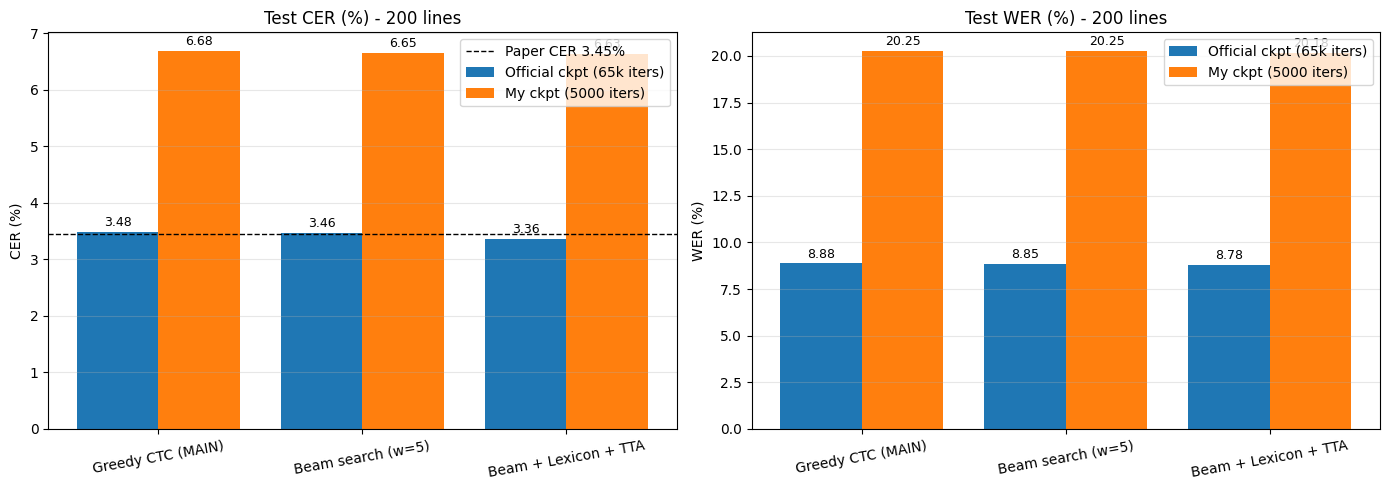

In [14]:
# ===== Step 8b: Biểu đồ so sánh CER / WER giữa các checkpoint & kiểu decoding =====
import numpy as np
import matplotlib.pyplot as plt

d = results_df.copy()
d["CER"] = d["CER (%)"].astype(float); d["WER"] = d["WER (%)"].astype(float)
models = list(dict.fromkeys(d["Model"]))
decs = list(dict.fromkeys(d["Decoding"]))
x, w = np.arange(len(decs)), 0.8 / len(models)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ("CER", "WER")):
    for i, mname in enumerate(models):
        vals = [d[(d.Model == mname) & (d.Decoding == dc)][metric].iloc[0] for dc in decs]
        bars = ax.bar(x + (i - (len(models) - 1) / 2) * w, vals, w, label=mname)
        ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=9)
    if metric == "CER":
        ax.axhline(3.45, color="k", ls="--", lw=1, label="Paper CER 3.45%")
    ax.set_xticks(x); ax.set_xticklabels([s.split(". ", 1)[-1] for s in decs], rotation=10)
    ax.set(title=f"Test {metric} (%) - {EVAL_SAMPLES} lines", ylabel=f"{metric} (%)")
    ax.grid(axis="y", alpha=.3); ax.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/cer_wer_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 🔍 Step 9: Qualitative Visual Error Inspection

Compare Ground Truth text with Baseline Greedy and Tuned predictions to observe how:
- Diacritics (`á`, `ơ`, `ư`, `ô`) are corrected by lexicon rescoring.
- Stroke breaks are resolved by TTA logit averaging.


In [15]:
def safe_ed(a, b):
    if a == b:
        return 0
    if isinstance(a, str) and isinstance(b, str):
        try:
            return editdistance_s.distance(a, b)
        except Exception:
            pass
    la, lb = len(a), len(b)
    if la == 0: return lb
    if lb == 0: return la
    prev = list(range(lb + 1))
    for i in range(1, la + 1):
        cur = [i]
        for j in range(1, lb + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + cost))
        prev = cur
    return prev[-1]

print("=" * 85)
print(f"{'#':<4} | {'METHOD':<18} | {'PREDICTED / GROUND TRUTH TEXT'}")
print("=" * 85)

for idx in range(min(6, len(ground_truths))):
    gt = ground_truths[idx]
    pred_g = greedy_results[idx]
    pred_t = tuned_results[idx]
    ed_g = safe_ed(pred_g, gt)
    ed_t = safe_ed(pred_t, gt)
    
    print(f"[{idx+1:02d}] | Ground Truth      | {gt}")
    print(f"     | Greedy CTC (ED={ed_g}) | {pred_g}")
    print(f"     | Tuned     (ED={ed_t}) | {pred_t}")
    status = "✨ Corrected" if ed_t < ed_g else ("✅ Exact Match" if ed_t == 0 else "Unchanged")
    print(f"     | Status             | {status}")
    print("-" * 85)


#    | METHOD             | PREDICTED / GROUND TRUTH TEXT
[01] | Ground Truth      | Có vị trí chiến lược quan trọng : nối liền Thái Bình Dương với Ấn Độ Dương,
     | Greedy CTC (ED=0) | Có vị trí chiến lược quan trọng : nối liền Thái Bình Dương với Ấn Độ Dương,
     | Tuned     (ED=0) | Có vị trí chiến lược quan trọng : nối liền Thái Bình Dương với Ấn Độ Dương,
     | Status             | ✅ Exact Match
-------------------------------------------------------------------------------------
[02] | Ground Truth      | đang hoành hành. Nhiều tài xế tha thiết " mời các lãnh đạo hãy bỏ xe biển số xanh theo xe đò
     | Greedy CTC (ED=3) | đang hoành hình. Nhiều tài xế thao thiết " mời các lãnh đạo hãy bỏ xe biển số xanh theo xe đi
     | Tuned     (ED=4) | đang hoình hình. Nhiều tài xế thao thiết " mời các lãnh đạo hãy bỏ xe biển số xanh theo xe đề
     | Status             | Unchanged
-------------------------------------------------------------------------------------
[03] | Ground Truth  

## 💾 Step 10: Checkpoint Archiving & Hugging Face Upload

Once your model finishes training, you can bundle checkpoints and logs into an archive for download from Kaggle, or directly push to Hugging Face Hub.


In [16]:
import os

archive_file = f"/kaggle/working/HTR-ConvText-{DATASET_NAME}-checkpoints.tar.gz"
output_folder = f"/kaggle/working/output/{EXP_NAME}"

if os.path.exists(output_folder):
    print(f"Archiving checkpoints from {output_folder}...")
    !tar -czf {archive_file} -C /kaggle/working/output {EXP_NAME}
    size_mb = os.path.getsize(archive_file) / (1024 * 1024)
    print(f"✅ Archive ready: {archive_file} ({size_mb:.1f} MB)")
    print("Download it from the 'Output' pane on the right side of the Kaggle notebook interface.")
else:
    print(f"No checkpoint directory at {output_folder} yet. Train the model in Step 6 to produce checkpoints.")

# Optional: Directly upload checkpoint to Hugging Face Hub
# from huggingface_hub import HfApi
# api = HfApi()
# api.upload_file(
#     path_or_fileobj=f"{output_folder}/best_CER.pth",
#     path_in_repo="best_CER.pth",
#     repo_id="YOUR_USERNAME/HTR-ConvText-Replication",
#     repo_type="model",
#     token="YOUR_HF_TOKEN"
# )


Archiving checkpoints from /kaggle/working/output/htr-convtext-vnondb-fast-multiscale...
✅ Archive ready: /kaggle/working/HTR-ConvText-vnondb-checkpoints.tar.gz (2967.2 MB)
Download it from the 'Output' pane on the right side of the Kaggle notebook interface.
